# Actor Critico

In [1]:
import random
import gymnasium as gym

import numpy as np
import collections
from tqdm import tqdm
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import os

os.environ['KMP_DUPLICATE_LIB_OK']='True'

# Reto 1
Crear las redes del actor y critico.
* Para el actor:
   * Capa de entrada lineal con numero de neuronas igual a la dimension de la capa oculta. Usar ReLU de funcion de activacion.
   * Capa de salida lineal con numero de neuronas igual a la dimension del espacio de acciones. Usar softmax como funcion de activacion.
* Para el critico:
   * Capa de entrada lineal con numero de neuronas igual a la dimension de la capa oculta. Usar ReLU de funcion de activacion.
   * Capa de salida lineal con solo una neurona.

In [2]:
class PolicyNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(PolicyNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc2(x), dim=1)

class ValueNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim):
        super(ValueNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return self.fc2(x)

# Reto 2
Crear red actor-critico.
* Similar a REINFORCE, no hay $\epsilon$-greedy ni bufer de experiencias.
* Es un algoritmo on-policy que entrena una red para la politica y otro para la funcion de valor.

In [3]:
class ActorCritic:
    def __init__(self, state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
                 gamma, device):
        # policy network
        self.actor = PolicyNet(state_dim, hidden_dim, action_dim).to(device)
        self.critic = ValueNet(state_dim, hidden_dim).to(device)  # Red de la funcion de valor
        # Optimizador de la red de la politica y la funcion de valor
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(),
                                                lr=actor_lr)
        self.critic_optimizer = torch.optim.Adam(self.critic.parameters(),
                                                 lr=critic_lr) 
        self.gamma = gamma
        self.device = device

    def take_action(self, state):
        state = torch.tensor([state], dtype=torch.float).to(self.device)
        probs = self.actor(state)
        action_dist = torch.distributions.Categorical(probs)
        action = action_dist.sample()
        return action.item()

    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'],
                              dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions']).view(-1, 1).to(
            self.device)
        rewards = torch.tensor(transition_dict['rewards'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'],
                                   dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'],
                             dtype=torch.float).view(-1, 1).to(self.device)

        # TD target
        td_target = rewards + self.gamma * self.critic(next_states) * (1 - dones)
        td_delta = td_target - self.critic(states)  # error TD
        log_probs = torch.log(self.actor(states).gather(1, actions))
        actor_loss = torch.mean(-log_probs * td_delta.detach())
        # Funcion de perdida de error cuadratico medio
        critic_loss = torch.mean(
            F.mse_loss(self.critic(states), td_target.detach()))
        self.actor_optimizer.zero_grad()
        self.critic_optimizer.zero_grad()
        actor_loss.backward()  # Calcular el gradiente de la red de la politica
        critic_loss.backward()  # Calcular el gradiente de la red de funcion de valor
        self.actor_optimizer.step()  # Actualizar los parametros de la red de politica
        self.critic_optimizer.step()  # Actualizar los parametros de la red de funcion de valor

# Reto 3
Entrenar la red actor-critico en el ambiente CartPole.

In [4]:
actor_lr = 1e-3
critic_lr = 1e-2
num_episodes = 1000
hidden_dim = 128
gamma = 0.98
device = torch.device("cuda") if torch.cuda.is_available() else torch.device(
    "cpu")

env_name = 'CartPole-v1'
env = gym.make(env_name)
env._max_episode_steps = 200
torch.manual_seed(0)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = ActorCritic(state_dim, hidden_dim, action_dim, actor_lr, critic_lr,
                    gamma, device)

return_list = []
for i in range(10):
    with tqdm(total=int(num_episodes/10), desc='Iteracion %d' % i) as pbar:
        for i_episode in range(int(num_episodes/10)):
            episode_return = 0
            transition_dict = {'states': [], 'actions': [], 'next_states': [], 'rewards': [], 'dones': []}
            state, _ = env.reset(seed = 0)
            done = False
            while not done:
                action = agent.take_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated
                transition_dict['states'].append(state)
                transition_dict['actions'].append(action)
                transition_dict['next_states'].append(next_state)
                transition_dict['rewards'].append(reward)
                transition_dict['dones'].append(done)
                state = next_state
                episode_return += reward
            return_list.append(episode_return)
            agent.update(transition_dict)
            if (i_episode+1) % 10 == 0:
                pbar.set_postfix({'Episodio': '%d' % (num_episodes/10 * i + i_episode+1), 'Retorno': '%.3f' % np.mean(return_list[-10:])})
            pbar.update(1)

Iteracion 0:   0%|          | 0/100 [00:00<?, ?it/s]C:\Users\Admin\AppData\Local\Temp\ipykernel_17096\2776757697.py:16: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:255.)
  state = torch.tensor([state], dtype=torch.float).to(self.device)
Iteracion 9: 100%|██████████| 100/100 [00:10<00:00,  9.21it/s, Episodio=1000, Retorno=200.000]


In [5]:
def moving_average(a, window_size):
    cumulative_sum = np.cumsum(np.insert(a, 0, 0)) 
    middle = (cumulative_sum[window_size:] - cumulative_sum[:-window_size]) / window_size
    r = np.arange(1, window_size-1, 2)
    begin = np.cumsum(a[:window_size-1])[::2] / r
    end = (np.cumsum(a[:-window_size:-1])[::2] / r)[::-1]
    return np.concatenate((begin, middle, end))

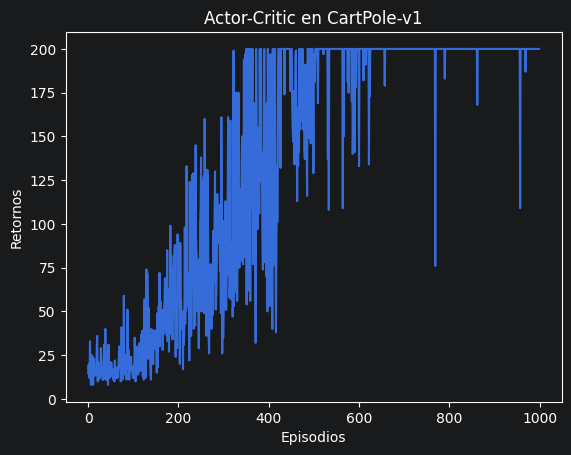

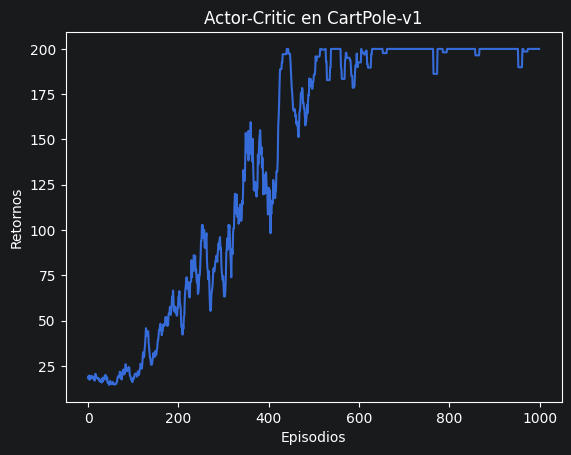

In [6]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('Actor-Critic en {}'.format(env_name))
plt.show()

mv_return = moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodios')
plt.ylabel('Retornos')
plt.title('Actor-Critic en {}'.format(env_name))
plt.show()

# Reto 4
Pruebe la red Actor-Critic entrenada en el sistema CartPole y vea lo resultados. Es bueno el modelo? Si? No? Por que?

In [8]:
#Obtener estado inicial
env = gym.make('CartPole-v1', render_mode = 'human')
for _ in range(10):
    state, _ = env.reset()
    episode_return = 0
    for step in range(500):
        with torch.no_grad():  # No necesitamos calcular gradientes en evaluación
            action = agent.take_action(state)    
        #Obtener s', r', done e info
        state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        episode_return += reward
    
        if done:
            break
    print(f'Retorno obtenido {episode_return}')
# Cerrar el ambiente
env.close()

Retorno obtenido 332.0
Retorno obtenido 383.0
Retorno obtenido 223.0
Retorno obtenido 380.0
Retorno obtenido 252.0
Retorno obtenido 314.0
Retorno obtenido 346.0
Retorno obtenido 432.0
Retorno obtenido 285.0
Retorno obtenido 225.0
